# **Explainable AI-Based Medical Image Classification Using Deep Convolutional Neural Networks**

**Problem Statement**

**Manual diagnosis of medical images is time-consuming and depends on expert radiologists. The objective is to develop a CNN-based system that automatically classifies medical images and provides visual explanations for its predictions, helping doctors make faster and more informed decisions.**

**Checking for GPU**

Verify that a GPU is available in this Colab runtime, since it substantially speeds up CNN training.

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**Install Required Libraries**

Install the extra Python packages (Kaggle API, OpenCV, plotting, and metrics libraries) used throughout this notebook.

In [ ]:
!pip install -q kaggle opencv-python matplotlib seaborn scikit-learn

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

**Downloading the Dataset**

Authenticate with the Kaggle API and download the chest X-ray dataset used for training and evaluation.

## Dataset Description

This project uses the **Chest X-Ray Images (Pneumonia)** dataset, publicly available on Kaggle:
[paultimothymooney/chest-xray-pneumonia](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia).

**Overview**
- The dataset contains **5,863 chest X-ray images (JPEG format)**, organized into two categories: **NORMAL** and **PNEUMONIA**.
- Images are anterior-posterior chest X-rays selected from retrospective cohorts of pediatric patients aged **one to five years** from Guangzhou Women and Children's Medical Center, Guangzhou.
- All images were initially screened for quality control, and diagnoses were graded by two expert physicians before being cleared for training use; a third expert reviewed the evaluation set to account for any grading errors.

**Folder Structure**
```
chest_xray/
├── train/
│   ├── NORMAL/
│   └── PNEUMONIA/
├── val/
│   ├── NORMAL/
│   └── PNEUMONIA/
└── test/
    ├── NORMAL/
    └── PNEUMONIA/
```

**Class Labels**
- `NORMAL`: X-rays of healthy lungs with no signs of infection.
- `PNEUMONIA`: X-rays showing signs of bacterial or viral pneumonia (opacities/infiltrates in the lung fields).

**Why this dataset is suitable**
- It is a well-known benchmark dataset for medical image classification tasks.
- The binary classification setup (Normal vs. Pneumonia) is ideal for building and evaluating a CNN-based image classifier.
- Its real-world clinical origin makes it a strong candidate for demonstrating **Explainable AI (XAI)** techniques (e.g., Grad-CAM) to visualize which regions of the X-ray influenced the model's prediction — critical for building trust in medical AI systems.

In [ ]:
!pip install -q --upgrade kaggle
!kaggle --version

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 5.6 MB/s eta 0:00:00
Kaggle CLI 2.2.4


In [ ]:
import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass("Enter your Kaggle API token: ")

Enter your Kaggle API token: ··········


In [ ]:
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [00:20<00:00, 120MB/s]



In [ ]:
!unzip -q chest-xray-pneumonia.zip -d /content/chest_xray

In [ ]:
!find /content/chest_xray -maxdepth 3 -type d

/content/chest_xray
/content/chest_xray/chest_xray
/content/chest_xray/chest_xray/train
/content/chest_xray/chest_xray/train/PNEUMONIA
/content/chest_xray/chest_xray/train/NORMAL
/content/chest_xray/chest_xray/val
/content/chest_xray/chest_xray/val/PNEUMONIA
/content/chest_xray/chest_xray/val/NORMAL
/content/chest_xray/chest_xray/__MACOSX
/content/chest_xray/chest_xray/__MACOSX/chest_xray
/content/chest_xray/chest_xray/chest_xray
/content/chest_xray/chest_xray/chest_xray/train
/content/chest_xray/chest_xray/chest_xray/val
/content/chest_xray/chest_xray/chest_xray/test
/content/chest_xray/chest_xray/test
/content/chest_xray/chest_xray/test/PNEUMONIA
/content/chest_xray/chest_xray/test/NORMAL


**Setting the Dataset Path**

Point to the extracted dataset folder so later cells can reference the train/val/test subdirectories.

In [ ]:
import os

base_dir = "/content/chest_xray/chest_xray"

print(os.listdir(base_dir))

['train', 'val', '__MACOSX', 'chest_xray', 'test']


**Counting the Images**

Count how many NORMAL and PNEUMONIA images exist in each split to check dataset size and balance.

In [ ]:
for folder in ["train", "val", "test"]:
    print("\n", folder)

    for category in ["NORMAL", "PNEUMONIA"]:
        path = os.path.join(base_dir, folder, category)
        count = len(os.listdir(path))
        print(category, ":", count)


 train
NORMAL : 1341
PNEUMONIA : 3875

 val
NORMAL : 8
PNEUMONIA : 8

 test
NORMAL : 234
PNEUMONIA : 390


**Visualising the Images**

Display a few sample X-rays from each class to get a visual feel for the data.

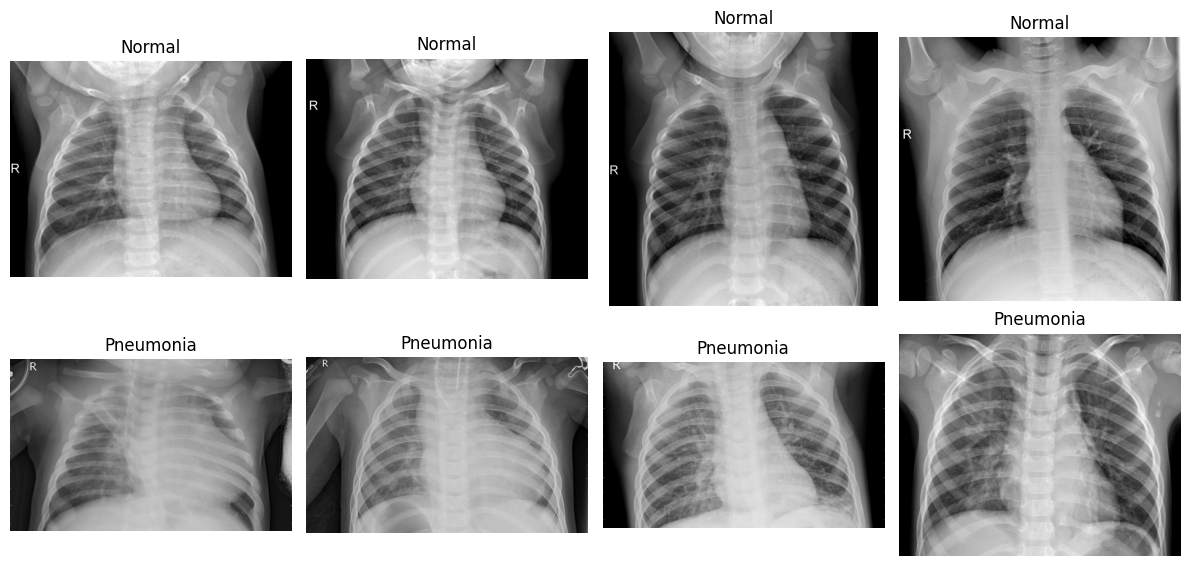

In [ ]:
import matplotlib.pyplot as plt
import cv2

normal_path = os.path.join(base_dir, "train", "NORMAL")
pneumonia_path = os.path.join(base_dir, "train", "PNEUMONIA")

normal_images = os.listdir(normal_path)
pneumonia_images = os.listdir(pneumonia_path)

plt.figure(figsize=(12, 6))

for i in range(4):
    img = cv2.imread(os.path.join(normal_path, normal_images[i]))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.axis("off")
    plt.title("Normal")

for i in range(4):
    img = cv2.imread(os.path.join(pneumonia_path, pneumonia_images[i]))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 4, i + 5)
    plt.imshow(img)
    plt.axis("off")
    plt.title("Pneumonia")

plt.tight_layout()
plt.show()

**Checking Image Dimensions**

Sample image dimensions across the dataset to confirm resizing to 224x224 is appropriate.

In [ ]:
sizes = []

for category in ["NORMAL", "PNEUMONIA"]:
    folder = os.path.join(base_dir, "train", category)

    for filename in os.listdir(folder)[:500]:
        path = os.path.join(folder, filename)
        img = cv2.imread(path)

        if img is not None:
            sizes.append(img.shape)

print("Number of images checked:", len(sizes))
print("Some image sizes:")

for size in sizes[:10]:
    print(size)

Number of images checked: 1000
Some image sizes:
(1086, 1414, 3)
(1522, 1940, 3)
(1688, 1654, 3)
(2364, 2518, 3)
(1296, 1416, 3)
(1140, 1462, 3)
(1392, 1746, 3)
(1090, 1408, 3)
(1167, 1384, 3)
(1328, 1440, 3)


**Checking Class Distribution Visually**

Plot the number of training images per class to visualize the class imbalance.

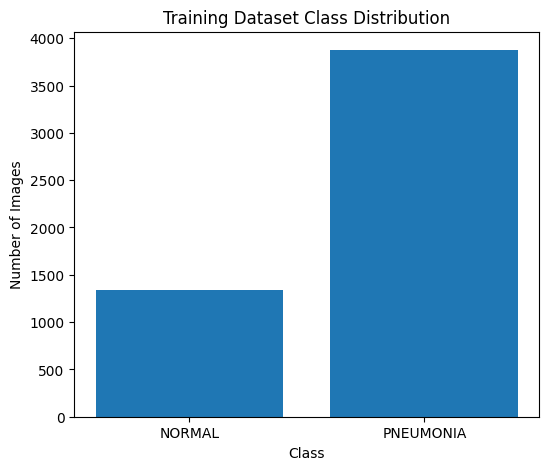

In [ ]:
train_counts = []

for category in ["NORMAL", "PNEUMONIA"]:
    path = os.path.join(base_dir, "train", category)
    train_counts.append(len(os.listdir(path)))

plt.figure(figsize=(6, 5))

plt.bar(["NORMAL", "PNEUMONIA"], train_counts)

plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.title("Training Dataset Class Distribution")

plt.show()

In [ ]:
train_dir = os.path.join(base_dir, "train")
test_dir = os.path.join(base_dir, "test")

print("Train path:", train_dir)
print("Test path:", test_dir)

Train path: /content/chest_xray/chest_xray/train
Test path: /content/chest_xray/chest_xray/test


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

**Data Augmentation**

Define image generators with augmentation (rotation, shifts, zoom, flip) to reduce overfitting and improve generalization.

In [ ]:
train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=10,
    width_shift_range=0.05,
    height_shift_range=0.05,
    zoom_range=0.1,
    horizontal_flip=True
)

test_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255
)

**Create Training Generator**

Build the generator that feeds augmented training images to the model in batches.

In [ ]:
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="training",
    shuffle=True,
    seed=SEED
)

Found 4173 images belonging to 2 classes.


**Creating Validation Generator**

Build the generator for the held-out validation split, used to monitor performance during training.

In [ ]:
val_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",
    shuffle=False,
    seed=SEED
)

Found 1043 images belonging to 2 classes.


**Creating Test Generator**

Build the generator for the untouched test split, used only for final evaluation.

In [ ]:
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    shuffle=False
)

Found 624 images belonging to 2 classes.


In [ ]:
print("Class mapping:")
print(train_generator.class_indices)

Class mapping:
{'NORMAL': 0, 'PNEUMONIA': 1}


**Handling Class Imbalance**

Compute class weights so the model isn't biased toward the majority (PNEUMONIA) class during training.

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(train_generator.classes)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_generator.classes
)

class_weights = dict(zip(classes, weights))

print(class_weights)

{np.int32(0): np.float64(1.9445479962721341), np.int32(1): np.float64(0.6730645161290323)}


# **Building Baseline CNN**

Define a simple CNN from scratch to serve as a performance baseline before trying pretrained architectures.

In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras import layers

baseline_model = Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.Conv2D(256, (3, 3), activation="relu"),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

In [ ]:
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,441 (1.61 MB)

 Trainable params: 421,441 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
baseline_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-6
)

In [ ]:
history_baseline = baseline_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 138s 1s/step - accuracy: 0.5207 - auc: 0.6055 - loss: 0.6823 - precision: 0.8083 - recall: 0.4652 - val_accuracy: 0.6127 - val_auc: 0.6746 - val_loss: 0.7333 - val_precision: 0.8732 - val_recall: 0.5600 - learning_rate: 0.0010
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 124s 949ms/step - accuracy: 0.6729 - auc: 0.7684 - loss: 0.5697 - precision: 0.9121 - recall: 0.6194 - val_accuracy: 0.6021 - val_auc: 0.8233 - val_loss: 0.6341 - val_precision: 0.9286 - val_recall: 0.5032 - learning_rate: 0.0010
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 141s 1s/step - accuracy: 0.8102 - auc: 0.9077 - loss: 0.3857 - precision: 0.9609 - recall: 0.7761 - val_accuracy: 0.7536 - val_auc: 0.9141 - val_loss: 0.5365 - val_precision: 0.9832 - val_recall: 0.6800 - learning_rate: 0.0010
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 134s 1s/step - accuracy: 0.8509 - auc: 0.9299 - loss: 0.3367 - precision: 0.9647 - recall: 0.8297 - val_accuracy: 0.7996 - val_auc: 0.9049 - val_loss: 0.433

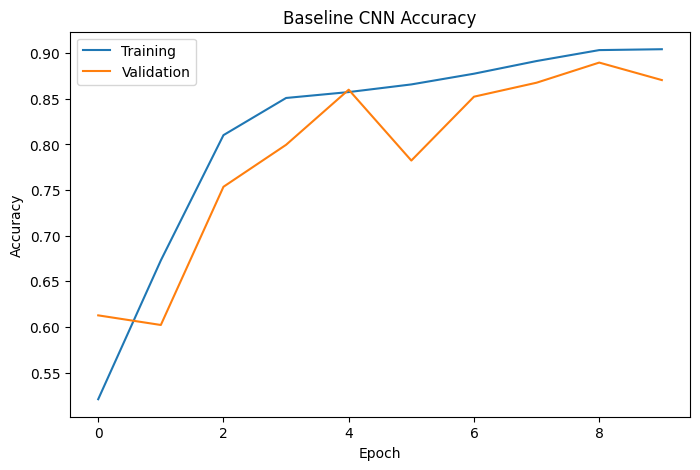

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history_baseline.history["accuracy"])
plt.plot(history_baseline.history["val_accuracy"])

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline CNN Accuracy")

plt.legend(["Training", "Validation"])
plt.show()

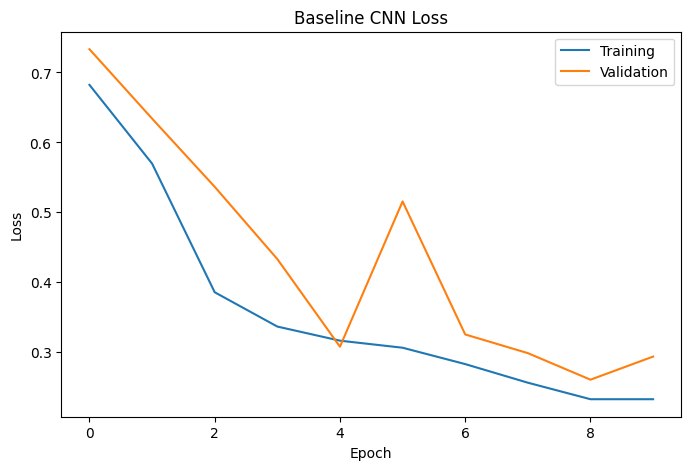

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history_baseline.history["loss"])
plt.plot(history_baseline.history["val_loss"])

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline CNN Loss")

plt.legend(["Training", "Validation"])
plt.show()

In [ ]:
baseline_results = baseline_model.evaluate(test_generator)

print("Test Loss:", baseline_results[0])
print("Test Accuracy:", baseline_results[1])
print("Test Precision:", baseline_results[2])
print("Test Recall:", baseline_results[3])
print("Test AUC:", baseline_results[4])

20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 306ms/step - accuracy: 0.8253 - auc: 0.8926 - loss: 0.4082 - precision: 0.8612 - recall: 0.8590
Test Loss: 0.40822580456733704
Test Accuracy: 0.8253205418586731
Test Precision: 0.8611825108528137
Test Recall: 0.8589743375778198
Test AUC: 0.8925817012786865


In [ ]:
test_generator.reset()

baseline_prob = baseline_model.predict(test_generator)

baseline_pred = (baseline_prob >= 0.5).astype(int).ravel()

true_labels = test_generator.classes

20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 217ms/step


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        true_labels,
        baseline_pred,
        target_names=["NORMAL", "PNEUMONIA"]
    )
)

              precision    recall  f1-score   support

      NORMAL       0.77      0.77      0.77       234
   PNEUMONIA       0.86      0.86      0.86       390

    accuracy                           0.83       624
   macro avg       0.81      0.81      0.81       624
weighted avg       0.83      0.83      0.83       624



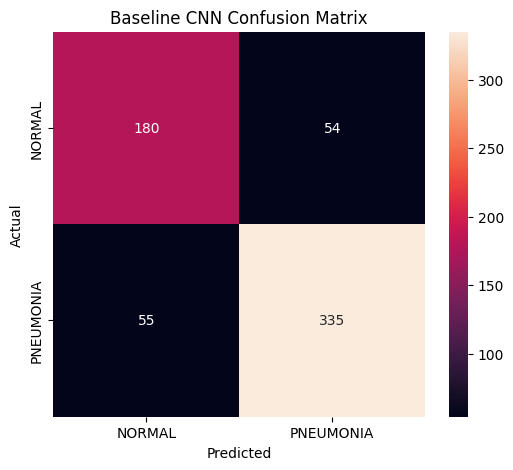

In [ ]:
cm = confusion_matrix(true_labels, baseline_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Baseline CNN Confusion Matrix")

plt.show()

In [ ]:
baseline_auc = roc_auc_score(
    true_labels,
    baseline_prob.ravel()
)

print("Baseline ROC-AUC:", baseline_auc)

Baseline ROC-AUC: 0.8931185623493316


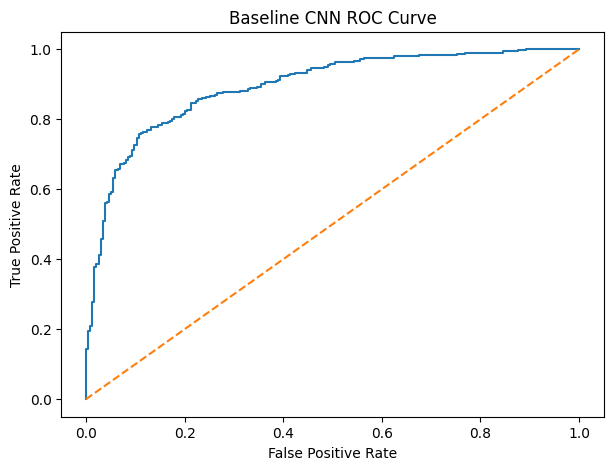

In [ ]:
fpr, tpr, thresholds = roc_curve(
    true_labels,
    baseline_prob.ravel()
)

plt.figure(figsize=(7, 5))

plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Baseline CNN ROC Curve")

plt.show()

# ***Can pretrained CNN architectures perform better than the baseline CNN for chest X-ray pneumonia classification?***

# **ResNet50**

Build a transfer-learning model on top of a frozen, ImageNet-pretrained ResNet50 backbone.

In [ ]:
from tensorflow.keras.applications import ResNet50

resnet_base = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

resnet_base.trainable = False

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


**Build ResNet Model**

Attach a global-pooling and dense classification head on top of the frozen ResNet50 backbone.

In [ ]:
resnet_model = Sequential([
    resnet_base,

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

In [ ]:
resnet_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [ ]:
history_resnet = resnet_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 106s 812ms/step - accuracy: 0.6885 - auc: 0.7536 - loss: 0.6352 - precision: 0.8692 - recall: 0.6835 - val_accuracy: 0.7661 - val_auc: 0.8500 - val_loss: 0.6220 - val_precision: 0.8969 - val_recall: 0.7742 - learning_rate: 2.0000e-04
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 106s 808ms/step - accuracy: 0.7340 - auc: 0.8063 - loss: 0.6183 - precision: 0.8920 - recall: 0.7303 - val_accuracy: 0.7622 - val_auc: 0.8511 - val_loss: 0.6132 - val_precision: 0.9085 - val_recall: 0.7561 - learning_rate: 2.0000e-04
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 105s 807ms/step - accuracy: 0.7707 - auc: 0.8379 - loss: 0.6058 - precision: 0.8973 - recall: 0.7806 - val_accuracy: 0.7593 - val_auc: 0.8537 - val_loss: 0.6210 - val_precision: 0.9441 - val_recall: 0.7187 - learning_rate: 4.0000e-05


In [ ]:
resnet_results = resnet_model.evaluate(test_generator)

print("ResNet50 Accuracy:", resnet_results[1])
print("ResNet50 Precision:", resnet_results[2])
print("ResNet50 Recall:", resnet_results[3])
print("ResNet50 AUC:", resnet_results[4])

20/20 ━━━━━━━━━━━━━━━━━━━━ 10s 465ms/step - accuracy: 0.7708 - auc: 0.8375 - loss: 0.6267 - precision: 0.7947 - recall: 0.8538
ResNet50 Accuracy: 0.7708333134651184
ResNet50 Precision: 0.79474937915802
ResNet50 Recall: 0.8538461327552795
ResNet50 AUC: 0.8374972343444824


# **DenseNet121**

Repeat the transfer-learning approach using a pretrained DenseNet121 backbone.

In [ ]:
from tensorflow.keras.applications import DenseNet121

densenet_base = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

densenet_base.trainable = False

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
densenet_model = Sequential([
    densenet_base,

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

In [ ]:
densenet_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [ ]:
history_densenet = densenet_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 174s 1s/step - accuracy: 0.8799 - auc: 0.9480 - loss: 0.2900 - precision: 0.9584 - recall: 0.8765 - val_accuracy: 0.9281 - val_auc: 0.9848 - val_loss: 0.1939 - val_precision: 0.9916 - val_recall: 0.9110 - learning_rate: 0.0010
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 104s 796ms/step - accuracy: 0.9252 - auc: 0.9755 - loss: 0.1971 - precision: 0.9790 - recall: 0.9190 - val_accuracy: 0.9597 - val_auc: 0.9897 - val_loss: 0.1274 - val_precision: 0.9803 - val_recall: 0.9652 - learning_rate: 0.0010
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 104s 792ms/step - accuracy: 0.9312 - auc: 0.9824 - loss: 0.1659 - precision: 0.9805 - recall: 0.9258 - val_accuracy: 0.9492 - val_auc: 0.9893 - val_loss: 0.1315 - val_precision: 0.9839 - val_recall: 0.9471 - learning_rate: 0.0010
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 103s 790ms/step - accuracy: 0.9363 - auc: 0.9835 - loss: 0.1583 - precision: 0.9794 - recall: 0.9339 - val_accuracy: 0.9569 - val_auc: 0.9942 - val_loss:

In [ ]:
densenet_results = densenet_model.evaluate(test_generator)

print("DenseNet121 Accuracy:", densenet_results[1])
print("DenseNet121 Precision:", densenet_results[2])
print("DenseNet121 Recall:", densenet_results[3])
print("DenseNet121 AUC:", densenet_results[4])

20/20 ━━━━━━━━━━━━━━━━━━━━ 17s 875ms/step - accuracy: 0.8958 - auc: 0.9573 - loss: 0.2733 - precision: 0.8860 - recall: 0.9564
DenseNet121 Accuracy: 0.8958333134651184
DenseNet121 Precision: 0.8859857320785522
DenseNet121 Recall: 0.9564102292060852
DenseNet121 AUC: 0.9572870135307312


# **EfficientNetB0**

Repeat the transfer-learning approach using a pretrained EfficientNetB0 backbone.

In [ ]:
from tensorflow.keras.applications import EfficientNetB0

efficientnet_base = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

efficientnet_base.trainable = False

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
efficientnet_model = Sequential([
    efficientnet_base,

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
])

In [ ]:
efficientnet_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [ ]:
history_efficientnet = efficientnet_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 167s 1s/step - accuracy: 0.5198 - auc: 0.5079 - loss: 0.7161 - precision: 0.7466 - recall: 0.5352 - val_accuracy: 0.7430 - val_auc: 0.7332 - val_loss: 0.6812 - val_precision: 0.7430 - val_recall: 1.0000 - learning_rate: 0.0010
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 99s 757ms/step - accuracy: 0.5711 - auc: 0.5198 - loss: 0.6941 - precision: 0.7547 - recall: 0.6261 - val_accuracy: 0.2570 - val_auc: 0.5000 - val_loss: 0.6950 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 102s 780ms/step - accuracy: 0.3204 - auc: 0.5048 - loss: 0.6932 - precision: 0.7284 - recall: 0.1358 - val_accuracy: 0.2570 - val_auc: 0.5000 - val_loss: 0.6947 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - learning_rate: 2.0000e-04


In [ ]:
efficientnet_results = efficientnet_model.evaluate(test_generator)

print("EfficientNetB0 Accuracy:", efficientnet_results[1])
print("EfficientNetB0 Precision:", efficientnet_results[2])
print("EfficientNetB0 Recall:", efficientnet_results[3])
print("EfficientNetB0 AUC:", efficientnet_results[4])

20/20 ━━━━━━━━━━━━━━━━━━━━ 16s 807ms/step - accuracy: 0.6250 - auc: 0.6799 - loss: 0.6872 - precision: 0.6250 - recall: 1.0000
EfficientNetB0 Accuracy: 0.625
EfficientNetB0 Precision: 0.625
EfficientNetB0 Recall: 1.0
EfficientNetB0 AUC: 0.6799145340919495


# **Model Comparison Table**

Summarize accuracy, precision, recall, and AUC across all four models to identify the best performer.

In [ ]:
results = pd.DataFrame({
    "Model": [
        "Baseline CNN",
        "ResNet50",
        "DenseNet121",
        "EfficientNetB0"
    ],
    "Accuracy": [
        baseline_results[1],
        resnet_results[1],
        densenet_results[1],
        efficientnet_results[1]
    ],
    "Precision": [
        baseline_results[2],
        resnet_results[2],
        densenet_results[2],
        efficientnet_results[2]
    ],
    "Recall": [
        baseline_results[3],
        resnet_results[3],
        densenet_results[3],
        efficientnet_results[3]
    ],
    "AUC": [
        baseline_results[4],
        resnet_results[4],
        densenet_results[4],
        efficientnet_results[4]
    ]
})

results

,Model,Accuracy,Precision,Recall,AUC
0,Baseline CNN,0.825321,0.861183,0.858974,0.892582
1,ResNet50,0.770833,0.794749,0.853846,0.837497
2,DenseNet121,0.895833,0.885986,0.956410,0.957287
3,EfficientNetB0,0.625000,0.625000,1.000000,0.679915


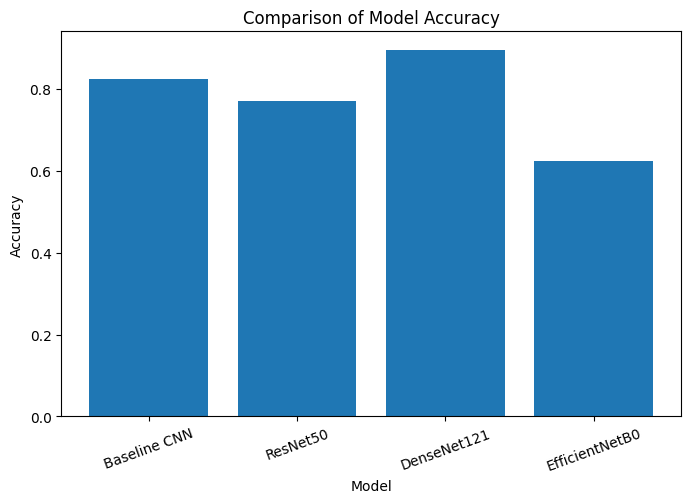

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(results["Model"], results["Accuracy"])

plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Comparison of Model Accuracy")

plt.xticks(rotation=20)
plt.show()

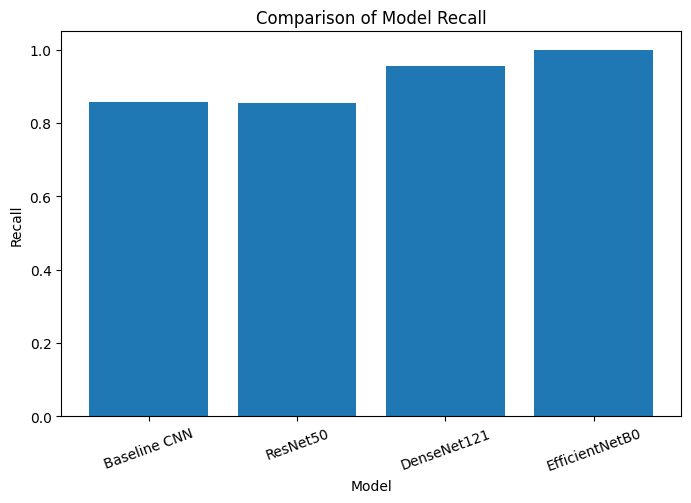

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(results["Model"], results["Recall"])

plt.ylabel("Recall")
plt.xlabel("Model")
plt.title("Comparison of Model Recall")

plt.xticks(rotation=20)
plt.show()

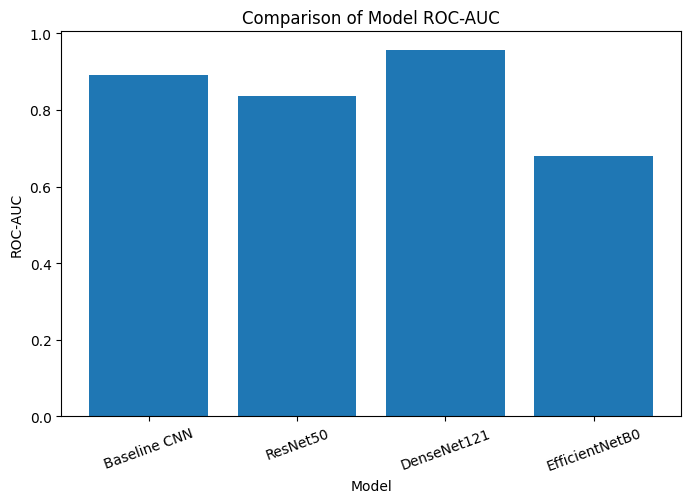

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(results["Model"], results["AUC"])

plt.ylabel("ROC-AUC")
plt.xlabel("Model")
plt.title("Comparison of Model ROC-AUC")

plt.xticks(rotation=20)
plt.show()

In [ ]:
best_model_name = results.loc[
    results["AUC"].idxmax(),
    "Model"
]

print("Best model based on AUC:", best_model_name)

Best model based on AUC: DenseNet121


**Analyze all model predictions**

Generate predictions and confusion matrices for every trained model on the test set.

In [ ]:
from sklearn.metrics import confusion_matrix

models = {
    "Baseline CNN": baseline_model,
    "ResNet50": resnet_model,
    "DenseNet121": densenet_model,
    "EfficientNetB0": efficientnet_model
}

for name, model in models.items():

    test_generator.reset()

    prob = model.predict(test_generator, verbose=0)
    pred = (prob >= 0.5).astype(int).ravel()

    cm = confusion_matrix(true_labels, pred)

    print("\n", name)
    print(cm)


 Baseline CNN
[[180  54]
 [ 55 335]]

 ResNet50
[[148  86]
 [ 57 333]]

 DenseNet121
[[186  48]
 [ 17 373]]

 EfficientNetB0
[[  0 234]
 [  0 390]]


# **Detailed DenseNet121 evaluation**

Take a closer look at DenseNet121, the best-performing model, with a full classification report and confusion matrix.

In [ ]:
test_generator.reset()

densenet_prob = densenet_model.predict(
    test_generator,
    verbose=0
).ravel()

densenet_pred = (densenet_prob >= 0.5).astype(int)

print(
    classification_report(
        true_labels,
        densenet_pred,
        target_names=["NORMAL", "PNEUMONIA"]
    )
)

              precision    recall  f1-score   support

      NORMAL       0.92      0.79      0.85       234
   PNEUMONIA       0.89      0.96      0.92       390

    accuracy                           0.90       624
   macro avg       0.90      0.88      0.89       624
weighted avg       0.90      0.90      0.89       624



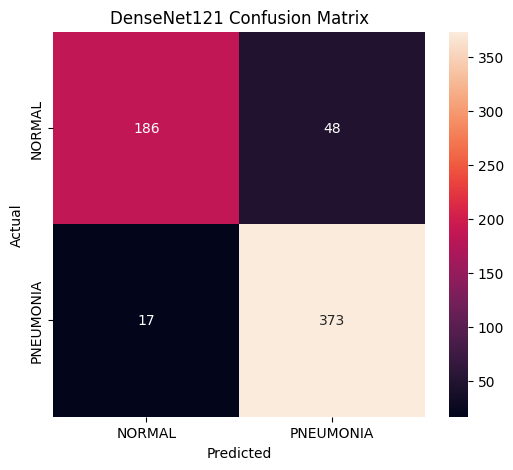

In [ ]:
cm = confusion_matrix(true_labels, densenet_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("DenseNet121 Confusion Matrix")

plt.show()

**Among the evaluated architectures, DenseNet121 achieved the best overall performance, obtaining an accuracy of 89.58% and ROC-AUC of 0.9573. It also achieved a recall of 95.64%, with only 17 false-negative predictions in the test set. The baseline CNN and ResNet50 produced higher numbers of false negatives, while EfficientNetB0 showed a severe prediction bias toward the pneumonia class.**

# **Fine tuning DenseNet121**

Unfreeze the last 40 layers of the DenseNet121 backbone and retrain at a low learning rate to squeeze out extra performance beyond the frozen-base model.

In [ ]:
val_datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

val_generator = val_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="binary",
    subset="validation",
    shuffle=False,
    seed=SEED
)

print(val_generator.class_indices)

Found 1043 images belonging to 2 classes.
{'NORMAL': 0, 'PNEUMONIA': 1}


In [ ]:
classes = np.unique(train_generator.classes)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_generator.classes
)

class_weights = dict(zip(classes, weights))

print(class_weights)

{np.int32(0): np.float64(1.9445479962721341), np.int32(1): np.float64(0.6730645161290323)}


In [ ]:
for i, layer in enumerate(densenet_base.layers):
    print(i, layer.name, layer.trainable)

0 input_layer_3 False
1 zero_padding2d False
2 conv1_conv False
3 conv1_bn False
4 conv1_relu False
5 zero_padding2d_1 False
6 pool1 False
7 conv2_block1_0_bn False
8 conv2_block1_0_relu False
9 conv2_block1_1_conv False
10 conv2_block1_1_bn False
11 conv2_block1_1_relu False
12 conv2_block1_2_conv False
13 conv2_block1_concat False
14 conv2_block2_0_bn False
15 conv2_block2_0_relu False
16 conv2_block2_1_conv False
17 conv2_block2_1_bn False
18 conv2_block2_1_relu False
19 conv2_block2_2_conv False
20 conv2_block2_concat False
21 conv2_block3_0_bn False
22 conv2_block3_0_relu False
23 conv2_block3_1_conv False
24 conv2_block3_1_bn False
25 conv2_block3_1_relu False
26 conv2_block3_2_conv False
27 conv2_block3_concat False
28 conv2_block4_0_bn False
29 conv2_block4_0_relu False
30 conv2_block4_1_conv False
31 conv2_block4_1_bn False
32 conv2_block4_1_relu False
33 conv2_block4_2_conv False
34 conv2_block4_concat False
35 conv2_block5_0_bn False
36 conv2_block5_0_relu False
37 conv2_blo

In [ ]:
densenet_base.trainable = True

for layer in densenet_base.layers[:-40]:
    layer.trainable = False

for layer in densenet_base.layers[-40:]:
    layer.trainable = True

print("Trainable layers:", sum(layer.trainable for layer in densenet_base.layers))

Trainable layers: 40


In [ ]:
densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [ ]:
fine_tune_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

fine_tune_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=1e-7
)

In [ ]:
history_finetune = densenet_model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    class_weight=class_weights,
    callbacks=[fine_tune_stop, fine_tune_lr]
)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 197s 1s/step - accuracy: 0.9128 - auc: 0.9695 - loss: 0.4390 - precision: 0.9031 - recall: 0.9887 - val_accuracy: 0.9281 - val_auc: 0.9923 - val_loss: 0.1669 - val_precision: 0.9916 - val_recall: 0.9110 - learning_rate: 1.0000e-05
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 101s 769ms/step - accuracy: 0.9504 - auc: 0.9841 - loss: 0.1770 - precision: 0.9665 - recall: 0.9668 - val_accuracy: 0.9204 - val_auc: 0.9923 - val_loss: 0.1798 - val_precision: 0.9915 - val_recall: 0.9006 - learning_rate: 1.0000e-05
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 140s 757ms/step - accuracy: 0.9427 - auc: 0.9812 - loss: 0.1821 - precision: 0.9729 - recall: 0.9494 - val_accuracy: 0.9128 - val_auc: 0.9932 - val_loss: 0.1990 - val_precision: 0.9928 - val_recall: 0.8890 - learning_rate: 1.0000e-05
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 96s 734ms/step - accuracy: 0.9478 - auc: 0.9847 - loss: 0.1535 - precision: 0.9813 - recall: 0.9477 - val_accuracy: 0.9128 - val_auc: 0.9933 

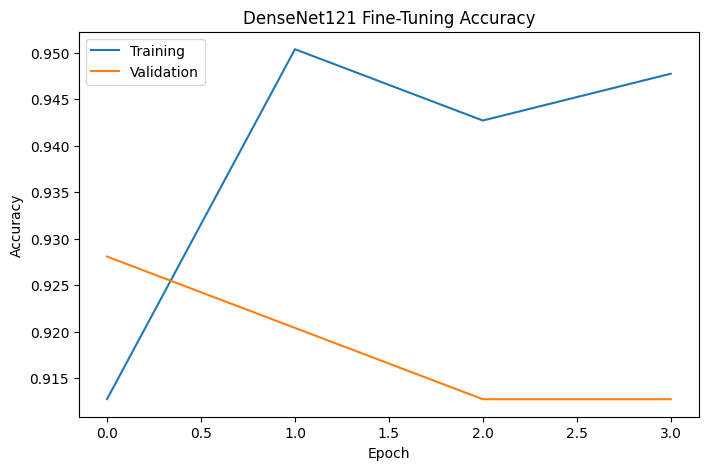

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history_finetune.history["accuracy"])
plt.plot(history_finetune.history["val_accuracy"])

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("DenseNet121 Fine-Tuning Accuracy")

plt.legend(["Training", "Validation"])
plt.show()

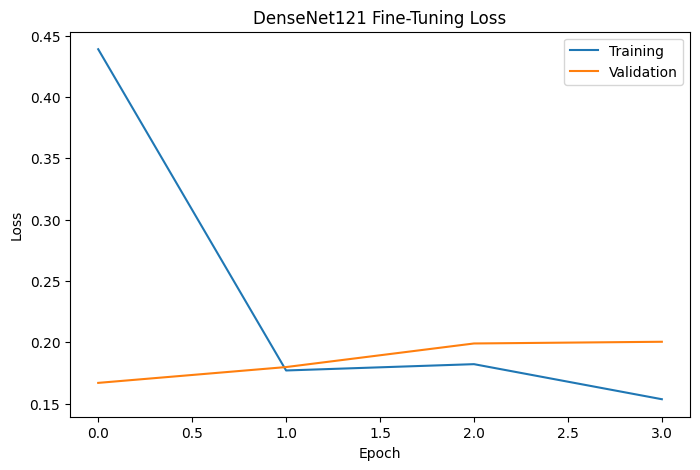

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history_finetune.history["loss"])
plt.plot(history_finetune.history["val_loss"])

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DenseNet121 Fine-Tuning Loss")

plt.legend(["Training", "Validation"])
plt.show()

In [ ]:
finetuned_results = densenet_model.evaluate(
    test_generator,
    verbose=1
)

print("Fine-tuned DenseNet121 Accuracy:", finetuned_results[1])
print("Fine-tuned DenseNet121 Precision:", finetuned_results[2])
print("Fine-tuned DenseNet121 Recall:", finetuned_results[3])
print("Fine-tuned DenseNet121 AUC:", finetuned_results[4])

20/20 ━━━━━━━━━━━━━━━━━━━━ 15s 736ms/step - accuracy: 0.8990 - auc: 0.9637 - loss: 0.2605 - precision: 0.8940 - recall: 0.9513
Fine-tuned DenseNet121 Accuracy: 0.8990384340286255
Fine-tuned DenseNet121 Precision: 0.8939759135246277
Fine-tuned DenseNet121 Recall: 0.9512820243835449
Fine-tuned DenseNet121 AUC: 0.9637463688850403


In [ ]:
test_generator.reset()

finetuned_prob = densenet_model.predict(
    test_generator,
    verbose=0
).ravel()

finetuned_pred = (finetuned_prob >= 0.5).astype(int)

true_labels = test_generator.classes

In [ ]:
print(
    classification_report(
        true_labels,
        finetuned_pred,
        target_names=["NORMAL", "PNEUMONIA"]
    )
)

              precision    recall  f1-score   support

      NORMAL       0.91      0.81      0.86       234
   PNEUMONIA       0.89      0.95      0.92       390

    accuracy                           0.90       624
   macro avg       0.90      0.88      0.89       624
weighted avg       0.90      0.90      0.90       624



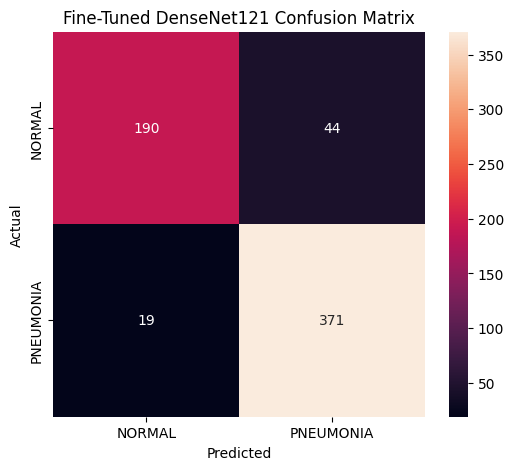

In [ ]:
cm = confusion_matrix(
    true_labels,
    finetuned_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Fine-Tuned DenseNet121 Confusion Matrix")

plt.show()

In [ ]:
finetuned_auc = roc_auc_score(
    true_labels,
    finetuned_prob
)

print("Fine-tuned DenseNet121 ROC-AUC:", finetuned_auc)

Fine-tuned DenseNet121 ROC-AUC: 0.9636642559719483


# **Compare original vs fine-tuned DenseNet121**

Check whether unfreezing and fine-tuning actually improved on the frozen-base DenseNet121 results.

In [ ]:
densenet_comparison = pd.DataFrame({
    "Model": [
        "DenseNet121",
        "Fine-Tuned DenseNet121"
    ],
    "Accuracy": [
        densenet_results[1],
        finetuned_results[1]
    ],
    "Precision": [
        densenet_results[2],
        finetuned_results[2]
    ],
    "Recall": [
        densenet_results[3],
        finetuned_results[3]
    ],
    "AUC": [
        densenet_results[4],
        finetuned_results[4]
    ]
})

densenet_comparison

,Model,Accuracy,Precision,Recall,AUC
0,DenseNet121,0.895833,0.885986,0.956410,0.957287
1,Fine-Tuned DenseNet121,0.899038,0.893976,0.951282,0.963746


In [ ]:
for i, layer in enumerate(densenet_base.layers):
    if len(layer.output.shape) == 4:
        print(i, layer.name, layer.output.shape)

0 input_layer_3 (None, 224, 224, 3)
1 zero_padding2d (None, 230, 230, 3)
2 conv1_conv (None, 112, 112, 64)
3 conv1_bn (None, 112, 112, 64)
4 conv1_relu (None, 112, 112, 64)
5 zero_padding2d_1 (None, 114, 114, 64)
6 pool1 (None, 56, 56, 64)
7 conv2_block1_0_bn (None, 56, 56, 64)
8 conv2_block1_0_relu (None, 56, 56, 64)
9 conv2_block1_1_conv (None, 56, 56, 128)
10 conv2_block1_1_bn (None, 56, 56, 128)
11 conv2_block1_1_relu (None, 56, 56, 128)
12 conv2_block1_2_conv (None, 56, 56, 32)
13 conv2_block1_concat (None, 56, 56, 96)
14 conv2_block2_0_bn (None, 56, 56, 96)
15 conv2_block2_0_relu (None, 56, 56, 96)
16 conv2_block2_1_conv (None, 56, 56, 128)
17 conv2_block2_1_bn (None, 56, 56, 128)
18 conv2_block2_1_relu (None, 56, 56, 128)
19 conv2_block2_2_conv (None, 56, 56, 32)
20 conv2_block2_concat (None, 56, 56, 128)
21 conv2_block3_0_bn (None, 56, 56, 128)
22 conv2_block3_0_relu (None, 56, 56, 128)
23 conv2_block3_1_conv (None, 56, 56, 128)
24 conv2_block3_1_bn (None, 56, 56, 128)
25 conv2

# **Create Grad-CAM model**

Build a Grad-CAM model on top of DenseNet121 to visualize which regions of an X-ray drove its prediction.

In [ ]:
import tensorflow as tf
import numpy as np

feature_extractor = tf.keras.Model(
    inputs=densenet_base.input,
    outputs=densenet_base.get_layer("relu").output
)

print("Feature extractor ready")

Feature extractor ready


In [ ]:
last_conv_layer = densenet_base.get_layer("relu")

grad_model = tf.keras.models.Model(
    inputs=densenet_base.input,
    outputs=[
        last_conv_layer.output,
        densenet_model(densenet_base.input)
    ]
)

print("Grad-CAM model ready")

Grad-CAM model ready


In [ ]:
def make_gradcam_heatmap(img_array):

    with tf.GradientTape() as tape:

        features = feature_extractor(img_array, training=False)
        tape.watch(features)

        x = tf.keras.layers.GlobalAveragePooling2D()(features)
        x = densenet_model.layers[-3](x)
        x = densenet_model.layers[-2](x)
        predictions = densenet_model.layers[-1](x)

        class_score = predictions[:, 0]

    grads = tape.gradient(class_score, features)

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    features = features[0]

    heatmap = tf.reduce_sum(
        features * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) +
        tf.keras.backend.epsilon()
    )

    return heatmap.numpy()

In [ ]:
import random
import numpy as np

filepaths = np.array(test_generator.filepaths)
classes = np.array(test_generator.classes)

normal_images = filepaths[classes == 0]
pneumonia_images = filepaths[classes == 1]

img_path = random.choice(pneumonia_images.tolist())

print("Selected image:", img_path)

Selected image: /content/chest_xray/chest_xray/test/PNEUMONIA/person78_bacteria_385.jpeg


In [ ]:
from tensorflow.keras.utils import load_img, img_to_array

img = load_img(
    img_path,
    target_size=IMG_SIZE
)

img_array = img_to_array(img)

input_array = np.expand_dims(
    img_array / 255.0,
    axis=0
)

print("Input shape:", input_array.shape)

Input shape: (1, 224, 224, 3)


In [ ]:
prediction = densenet_model.predict(
    input_array,
    verbose=0
)[0][0]

if prediction >= 0.5:
    predicted_class = "PNEUMONIA"
    confidence = prediction
else:
    predicted_class = "NORMAL"
    confidence = 1 - prediction

print("Prediction:", predicted_class)
print("Confidence:", round(confidence * 100, 2), "%")

Prediction: PNEUMONIA
Confidence: 99.91 %


In [ ]:
heatmap = make_gradcam_heatmap(input_array)

print("Heatmap shape:", heatmap.shape)

Heatmap shape: (7, 7)


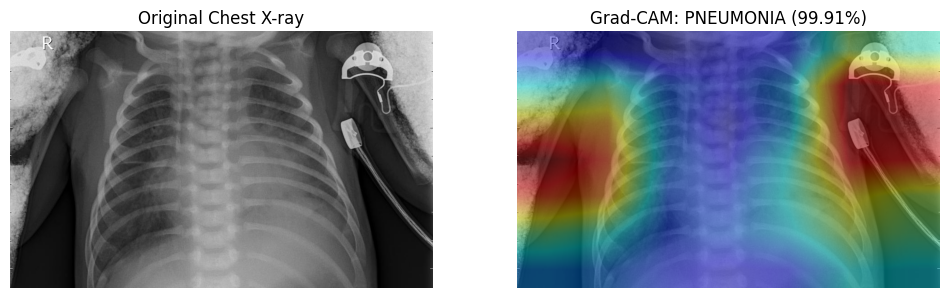

In [ ]:
import cv2
import matplotlib.pyplot as plt

original_img = cv2.imread(img_path)
original_img = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)

heatmap_resized = cv2.resize(
    heatmap,
    (original_img.shape[1], original_img.shape[0])
)

heatmap_uint8 = np.uint8(255 * heatmap_resized)

colored_heatmap = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

colored_heatmap = cv2.cvtColor(
    colored_heatmap,
    cv2.COLOR_BGR2RGB
)

overlay = cv2.addWeighted(
    original_img,
    0.6,
    colored_heatmap,
    0.4,
    0
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_img)
plt.title("Original Chest X-ray")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(overlay)
plt.title(
    f"Grad-CAM: {predicted_class} ({confidence*100:.2f}%)"
)
plt.axis("off")

plt.show()

In [ ]:
y_true = test_generator.classes

y_prob = densenet_model.predict(
    test_generator,
    verbose=1
).ravel()

y_pred = (y_prob >= 0.5).astype(int)

print("Total test images:", len(y_true))

20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 291ms/step
Total test images: 624


In [ ]:
tp_indices = np.where((y_true == 1) & (y_pred == 1))[0]
tn_indices = np.where((y_true == 0) & (y_pred == 0))[0]
fp_indices = np.where((y_true == 0) & (y_pred == 1))[0]
fn_indices = np.where((y_true == 1) & (y_pred == 0))[0]

print("True Positives:", len(tp_indices))
print("True Negatives:", len(tn_indices))
print("False Positives:", len(fp_indices))
print("False Negatives:", len(fn_indices))

True Positives: 371
True Negatives: 190
False Positives: 44
False Negatives: 19


In [ ]:
selected_indices = {
    "True Positive": random.choice(tp_indices.tolist()),
    "True Negative": random.choice(tn_indices.tolist()),
    "False Positive": random.choice(fp_indices.tolist()),
    "False Negative": random.choice(fn_indices.tolist())
}

for category, index in selected_indices.items():
    print(category)
    print(test_generator.filepaths[index])

True Positive
/content/chest_xray/chest_xray/test/PNEUMONIA/person31_virus_70.jpeg
True Negative
/content/chest_xray/chest_xray/test/NORMAL/NORMAL2-IM-0277-0001.jpeg
False Positive
/content/chest_xray/chest_xray/test/NORMAL/IM-0015-0001.jpeg
False Negative
/content/chest_xray/chest_xray/test/PNEUMONIA/person16_virus_47.jpeg


In [ ]:
def get_gradcam_image(index):

    path = test_generator.filepaths[index]

    img = load_img(
        path,
        target_size=IMG_SIZE
    )

    img_array = img_to_array(img)

    input_array = np.expand_dims(
        img_array / 255.0,
        axis=0
    )

    prediction = densenet_model.predict(
        input_array,
        verbose=0
    )[0][0]

    if prediction >= 0.5:
        predicted_class = "PNEUMONIA"
        confidence = prediction
    else:
        predicted_class = "NORMAL"
        confidence = 1 - prediction

    heatmap = make_gradcam_heatmap(
        input_array
    )

    original_img = cv2.imread(path)
    original_img = cv2.cvtColor(
        original_img,
        cv2.COLOR_BGR2RGB
    )

    heatmap_resized = cv2.resize(
        heatmap,
        (original_img.shape[1], original_img.shape[0])
    )

    heatmap_uint8 = np.uint8(
        255 * heatmap_resized
    )

    colored_heatmap = cv2.applyColorMap(
        heatmap_uint8,
        cv2.COLORMAP_JET
    )

    colored_heatmap = cv2.cvtColor(
        colored_heatmap,
        cv2.COLOR_BGR2RGB
    )

    overlay = cv2.addWeighted(
        original_img,
        0.6,
        colored_heatmap,
        0.4,
        0
    )

    return original_img, overlay, predicted_class, confidence

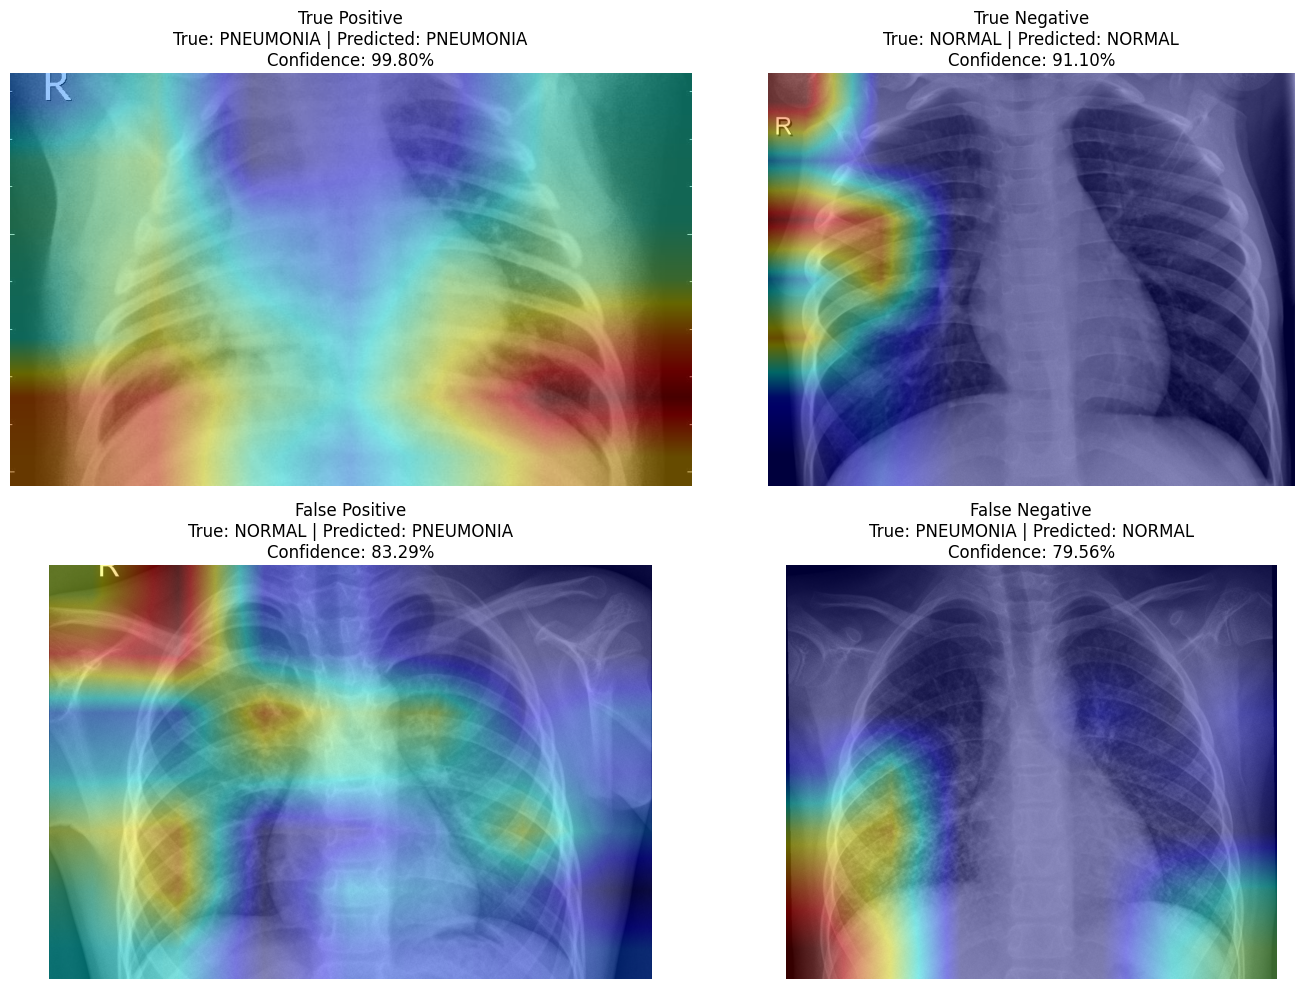

In [ ]:
fig, axes = plt.subplots(
    2,
    2,
    figsize=(14, 10)
)

for ax, (category, index) in zip(
    axes.ravel(),
    selected_indices.items()
):

    original_img, overlay, predicted_class, confidence = get_gradcam_image(index)

    ax.imshow(overlay)

    true_class = (
        "PNEUMONIA"
        if y_true[index] == 1
        else "NORMAL"
    )

    ax.set_title(
        f"{category}\n"
        f"True: {true_class} | "
        f"Predicted: {predicted_class}\n"
        f"Confidence: {confidence*100:.2f}%"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

os.makedirs(
    "/content/results",
    exist_ok=True
)

fig.savefig(
    "/content/results/gradcam_error_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

print("Saved successfully")

Saved successfully


In [ ]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"],
    digits=4
)

print(report)

              precision    recall  f1-score   support

      NORMAL     0.9091    0.8120    0.8578       234
   PNEUMONIA     0.8940    0.9513    0.9217       390

    accuracy                         0.8990       624
   macro avg     0.9015    0.8816    0.8898       624
weighted avg     0.8996    0.8990    0.8978       624



[[190  44]
 [ 19 371]]


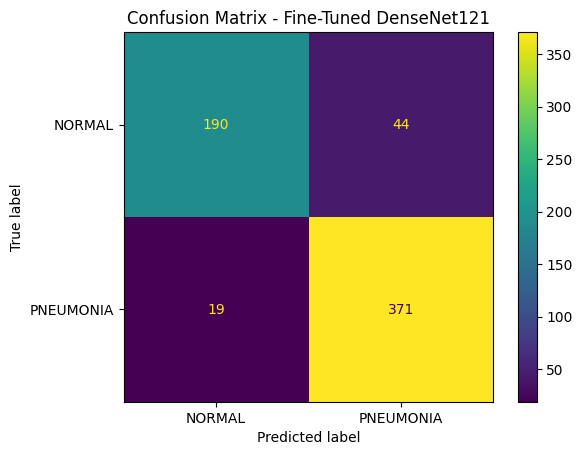

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred
)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

disp.plot()
plt.title("Confusion Matrix - Fine-Tuned DenseNet121")
plt.show()

# Explainable AI-Based Chest X-ray Classification — Summary

## Objective
Build a CNN-based system to classify chest X-rays as **NORMAL** or **PNEUMONIA**, and use **Grad-CAM** to visually explain model predictions — addressing the fact that manual radiology review is slow and expert-dependent.

## Dataset
- **Source:** Kaggle `paultimothymooney/chest-xray-pneumonia`
- **Split:** Train (4,173 images after an 80/20 train/val split), Validation (1,043), Test (624)
- **Classes:** NORMAL vs PNEUMONIA (imbalanced — handled via `compute_class_weight`)
- Images resized to 224×224, normalized (`rescale=1./255`), with augmentation on the training set (rotation, shift, zoom, horizontal flip)

## Modeling Approach
Four architectures were trained and compared, all using binary cross-entropy loss, Adam optimizer, and `EarlyStopping`/`ReduceLROnPlateau` callbacks:

1. **Baseline CNN** — custom 4-block Conv2D/MaxPooling stack + GlobalAveragePooling + Dense head
2. **ResNet50** (ImageNet weights, frozen base) + GAP + Dense head
3. **DenseNet121** (ImageNet weights, frozen base) + GAP + Dense head
4. **EfficientNetB0** (ImageNet weights, frozen base) + GAP + Dense head

Each model was evaluated on the held-out test set using Accuracy, Precision, Recall, and ROC-AUC.

## Model Comparison (Test Set)

| Model | Accuracy | Precision | Recall | ROC-AUC |
|---|---|---|---|---|
| Baseline CNN | 82.5% | 86.1% | 85.9% | 0.893 |
| ResNet50 | 77.1% | 79.5% | 85.4% | 0.837 |
| **DenseNet121** | **89.6%** | 88.6% | **95.6%** | **0.957** |
| EfficientNetB0 | 62.5% | 62.5% | 100%* | 0.680 |

\*EfficientNetB0 showed a strong bias toward predicting PNEUMONIA for every case (perfect recall but poor precision), rather than genuinely discriminating between classes.

**DenseNet121 was selected as the best-performing model**, based on the highest AUC and recall, with only 17 false negatives on the test set — an important property for a screening tool where missing true pneumonia cases is costly.

## Fine-Tuning DenseNet121
The last 40 layers of the DenseNet121 base were unfrozen and retrained at a low learning rate (1e-5):

| Model | Accuracy | Precision | Recall | ROC-AUC |
|---|---|---|---|---|
| DenseNet121 (frozen base) | 89.6% | 88.6% | 95.6% | 0.957 |
| DenseNet121 (fine-tuned) | 89.9% | 89.4% | 95.1% | 0.964 |

Fine-tuning gave a modest improvement in accuracy and AUC, with recall staying high (~95%). Final classification report on the test set (fine-tuned model):

| Class | Precision | Recall | F1 |
|---|---|---|---|
| NORMAL | 0.91 | 0.81 | 0.86 |
| PNEUMONIA | 0.89 | 0.95 | 0.92 |
| **Overall accuracy** | | | **0.90** |

## Explainability: Grad-CAM
To make predictions interpretable, the notebook implements **Grad-CAM** using the last convolutional feature map of DenseNet121 (`relu` layer):
- Computes gradients of the predicted class score with respect to the final conv-layer activations
- Produces a heatmap highlighting the image regions most influential to the prediction
- Overlays the heatmap on the original X-ray for visual interpretation

### Error Analysis with Grad-CAM
The notebook selects one example from each confusion-matrix category — **True Positive, True Negative, False Positive, False Negative** — and visualizes the Grad-CAM heatmap for each, alongside the true label, predicted label, and confidence score. This helps assess *where* the model is "looking" when it makes correct vs. incorrect predictions, and whether misclassifications correspond to genuinely ambiguous or anatomically unusual regions.

## Key Takeaways
- Transfer learning with **DenseNet121** clearly outperformed a custom baseline CNN and other pretrained backbones (ResNet50, EfficientNetB0) on this dataset.
- Fine-tuning the top layers of DenseNet121 yielded a small additional gain in AUC and accuracy.
- Grad-CAM visualizations add interpretability, letting a clinician cross-check whether the model's attention aligns with plausible pathological regions rather than spurious artifacts.
- EfficientNetB0's collapse to a "predict pneumonia" strategy highlights the importance of comparing multiple architectures and metrics (not accuracy alone) rather than assuming pretrained models automatically transfer well.